# 🧠 CSP + LDA — Motor Imagery EEG
Runs LORO-CV for **all 11 subjects** automatically.
Fast — no GPU needed.

## 1. Imports & config

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import mne
import torch
import torch.nn as nn
import torch.nn.functional as torch_func
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report)
from scipy.signal import butter, sosfilt, sosfilt_zi
from collections import deque
import joblib, time
warnings.filterwarnings("ignore")
mne.set_log_level("WARNING")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

def get_device():
    try:
        import torch_directml
        dev  = torch_directml.device(0)
        name = torch_directml.device_name(0)
        print(f"✅ AMD GPU via DirectML: {name}")
        return dev
    except:
        pass
    if torch.cuda.is_available():
        print(f"✅ CUDA GPU: {torch.cuda.get_device_name(0)}")
        return torch.device("cuda")
    print("⚠️  No GPU — running on CPU")
    return torch.device("cpu")

DEVICE     = get_device()
PIN_MEMORY = False

ROOT       = os.getcwd()
N_SUBJECTS = 11
N_SESSIONS = {i: 6 for i in range(1, 12)}
N_SESSIONS[2] = 4
N_RUNS     = 3
SFREQ      = 256

EEG_CHANNELS = ["F3","F1","Fz","F2","F4",
                 "C3","C1","Cz","C2","C4",
                 "CPz","P3","P1","Pz","P2",
                 "P4","POz","O1","Oz","O2"]
FMIN, FMAX = 8.0, 30.0
TMIN, TMAX = 0.5, 4.5

print(f"Root: {ROOT}")
print("Config ready ✅")

✅ AMD GPU via DirectML: AMD Radeon RX 6600M 
Root: C:\Users\giaco\Documents\GitHub\Multiclass_NN\data\EEGMI
Config ready ✅


## 2. Data loader

In [3]:
def build_path(root, sub, ses, run, suffix):
    fname = f"sub-{sub:02d}_ses-{ses:02d}_task-MI_run-{run:02d}_{suffix}"
    return os.path.join(root, f"sub-{sub:02d}", f"ses-{ses:02d}", "eeg", fname)

def load_run(root, sub, ses, run):
    edf    = build_path(root, sub, ses, run, "eeg.edf")
    events = build_path(root, sub, ses, run, "events.tsv")
    if not os.path.exists(edf):
        return None, None
    raw = mne.io.read_raw_edf(edf, preload=True, verbose=False)
    avail = [c for c in EEG_CHANNELS if c in raw.ch_names]
    raw.pick(avail)
    raw.filter(FMIN, FMAX, method="iir",
               iir_params=dict(order=4, ftype="butter"), verbose=False)
    ev_df  = pd.read_csv(events, sep="\t")
    evs    = np.array([[int(r["sample"]), 0, 1 if r["trial_type"]=="action" else 0]
                        for _, r in ev_df.iterrows()])
    evs    = evs[np.argsort(evs[:,0])]
    epochs = mne.Epochs(raw, evs, event_id={"rest":0,"action":1},
                         tmin=TMIN, tmax=TMAX, baseline=None,
                         preload=True, verbose=False)
    X = epochs.get_data()
    y = epochs.events[:,2].astype(np.int64)
    keep = np.max(np.abs(X), axis=(1,2)) < 100e-6
    X, y = X[keep], y[keep]
    mu  = X.mean(axis=2, keepdims=True)
    std = X.std( axis=2, keepdims=True) + 1e-8
    return (X - mu) / std, y

def load_subject(root, sub):
    all_X, all_y, all_meta = [], [], []
    for ses in range(1, N_SESSIONS[sub]+1):
        for run in range(1, N_RUNS+1):
            X, y = load_run(root, sub, ses, run)
            if X is None or len(X) == 0:
                continue
            all_X.append(X); all_y.append(y)
            n = len(y)
            all_meta.extend([{"subject":sub,"session":ses,"run":run}]*n)
    if not all_X:
        return None, None, None
    return np.concatenate(all_X), np.concatenate(all_y), pd.DataFrame(all_meta)

print("Data loader ready ✅")

Data loader ready ✅


## 3. CSP + LDA pipeline

In [4]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline

N_CSP = 6

def build_csp_lda():
    return Pipeline([
        ("csp", CSP(n_components=N_CSP, reg=None, log=True, norm_trace=False)),
        ("lda", LinearDiscriminantAnalysis(solver="svd")),
    ])

print(f"CSP components: {N_CSP}")
print("CSP+LDA ready ✅")

CSP components: 6
CSP+LDA ready ✅


## 4. Train — all subjects, leave-one-run-out CV

In [4]:
SUBJECTS    = list(range(1, 12))   # ← change e.g. [1,2,3] to test a subset
all_results = []

for sub in SUBJECTS:
    print(f"\n{'='*50}")
    print(f"  sub-{sub:02d}")
    print(f"{'='*50}")

    X_sub, y_sub, meta_sub = load_subject(ROOT, sub)
    if X_sub is None:
        print(f"  ⚠️  No data found — skipping")
        continue

    n_ch, n_t = X_sub.shape[1], X_sub.shape[2]
    runs_X = [X_sub[meta_sub["run"].values==r] for r in range(1, N_RUNS+1)]
    runs_y = [y_sub[meta_sub["run"].values==r] for r in range(1, N_RUNS+1)]

    sub_preds, sub_true, sub_accs, sub_bals = [], [], [], []

    for fold in range(N_RUNS):
        X_te = runs_X[fold]; y_te = runs_y[fold]
        X_tr = np.concatenate([runs_X[i] for i in range(N_RUNS) if i != fold])
        y_tr = np.concatenate([runs_y[i] for i in range(N_RUNS) if i != fold])

        if len(X_te) == 0 or len(X_tr) == 0:
            continue

        pipe = build_csp_lda()
        t0   = time.perf_counter()
        pipe.fit(X_tr, y_tr)
        elapsed = time.perf_counter() - t0

        preds = pipe.predict(X_te)
        acc   = accuracy_score(y_te, preds)
        bal   = balanced_accuracy_score(y_te, preds)
        sub_accs.append(acc); sub_bals.append(bal)
        sub_preds.extend(preds); sub_true.extend(y_te)
        print(f"  run-{fold+1:02d} | acc={acc:.3f}  bal_acc={bal:.3f}  ({elapsed*1000:.0f} ms)")

        ckpt_path = f"checkpoint_csp_sub{sub:02d}_run{fold+1}.pkl"
        joblib.dump({"pipe": pipe}, ckpt_path)

    if sub_accs:
        mean_acc = np.mean(sub_accs); mean_bal = np.mean(sub_bals)
        print(f"\n  sub-{sub:02d} → acc={mean_acc:.3f} ± {np.std(sub_accs):.3f}  "
              f"bal_acc={mean_bal:.3f} ± {np.std(sub_bals):.3f}")
        all_results.append({"subject":sub, "acc":mean_acc, "bal_acc":mean_bal})
        print(classification_report(sub_true, sub_preds,
                                     target_names=["rest","action"], digits=3))

print(f"\n✅ Done — {len(all_results)}/{len(SUBJECTS)} subjects completed")


  sub-01
  run-01 | acc=0.689  bal_acc=0.689  (1911 ms)
  run-02 | acc=0.702  bal_acc=0.702  (1420 ms)
  run-03 | acc=0.730  bal_acc=0.730  (1273 ms)

  sub-01 → acc=0.707 ± 0.017  bal_acc=0.707 ± 0.017
              precision    recall  f1-score   support

        rest      0.700     0.730     0.715       627
      action      0.718     0.687     0.703       627

    accuracy                          0.709      1254
   macro avg      0.709     0.709     0.709      1254
weighted avg      0.709     0.709     0.709      1254


  sub-02
  run-01 | acc=0.603  bal_acc=0.603  (854 ms)
  run-02 | acc=0.668  bal_acc=0.665  (868 ms)
  run-03 | acc=0.568  bal_acc=0.568  (809 ms)

  sub-02 → acc=0.613 ± 0.041  bal_acc=0.612 ± 0.040
              precision    recall  f1-score   support

        rest      0.602     0.633     0.617       414
      action      0.623     0.592     0.607       424

    accuracy                          0.612       838
   macro avg      0.613     0.612     0.612       

## 5. Summary plot — all subjects

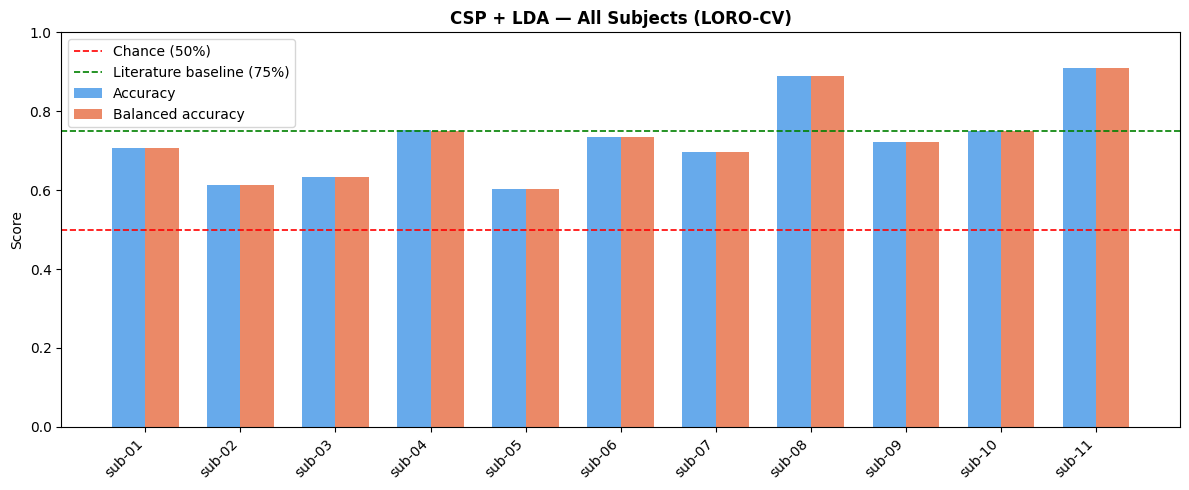


Subject      Accuracy    Bal.Acc
─────────────────────────────────
sub-01         0.707      0.707
sub-02         0.613      0.612
sub-03         0.634      0.634
sub-04         0.753      0.749
sub-05         0.604      0.604
sub-06         0.734      0.734
sub-07         0.697      0.697
sub-08         0.888      0.888
sub-09         0.721      0.721
sub-10         0.749      0.749
sub-11         0.909      0.909
─────────────────────────────────
MEAN            0.728      0.728
STD             0.095      0.095


In [5]:
def plot_all_subjects(results, method_name, out_file):
    """Bar chart of accuracy across all subjects."""
    subs = [r["subject"] for r in results]
    accs = [r["acc"]     for r in results]
    bals = [r["bal_acc"] for r in results]

    fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(subs))
    w = 0.35
    ax.bar(x - w/2, accs, w, label="Accuracy",          color="#4C9BE8", alpha=0.85)
    ax.bar(x + w/2, bals, w, label="Balanced accuracy", color="#E8754C", alpha=0.85)
    ax.axhline(0.50, color="red",   ls="--", lw=1.2, label="Chance (50%)")
    ax.axhline(0.75, color="green", ls="--", lw=1.2, label="Literature baseline (75%)")
    ax.set_xticks(x)
    ax.set_xticklabels([f"sub-{s:02d}" for s in subs], rotation=45, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("Score")
    ax.set_title(f"{method_name} — All Subjects (LORO-CV)", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.savefig(out_file, dpi=150); plt.show()

    print(f"\n{'Subject':<10} {'Accuracy':>10} {'Bal.Acc':>10}")
    print("─" * 33)
    for r in results:
        print(f"sub-{r['subject']:02d}    {r['acc']:>10.3f} {r['bal_acc']:>10.3f}")
    all_accs = [r["acc"]     for r in results]
    all_bals = [r["bal_acc"] for r in results]
    print("─" * 33)
    print(f"{'MEAN':<10} {np.mean(all_accs):>10.3f} {np.mean(all_bals):>10.3f}")
    print(f"{'STD':<10} {np.std(all_accs):>10.3f} {np.std(all_bals):>10.3f}")

plot_all_subjects(all_results, "CSP + LDA", "csp_all_subjects.png")

## 6. Real-time simulation — all subjects

sub-01: streaming… 

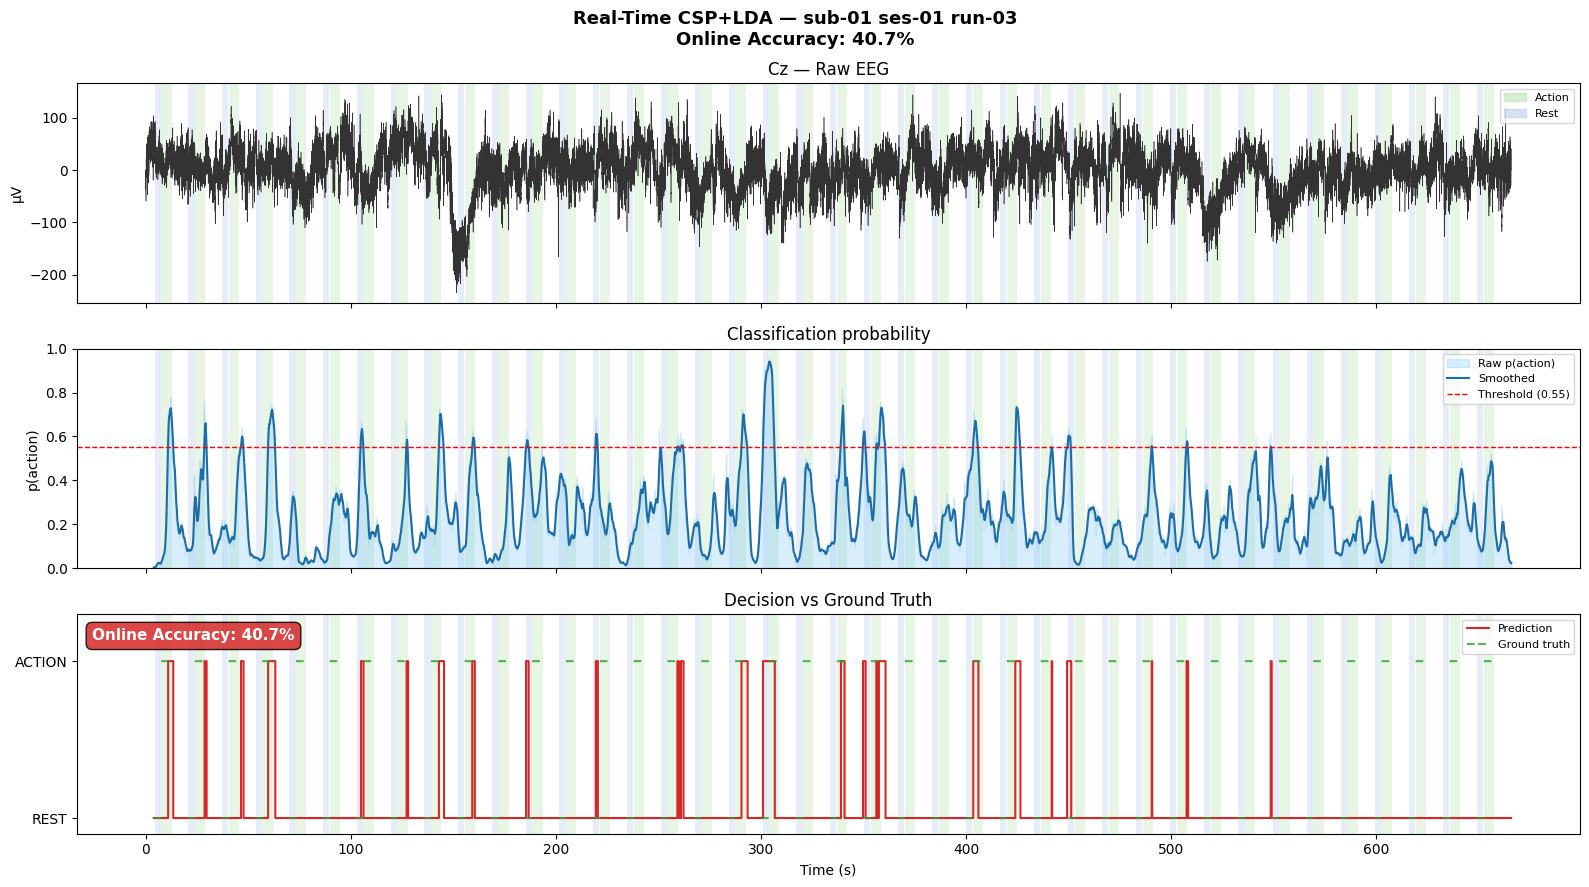

acc=40.7%  → saved realtime_figures/realtime_csp_sub01.png
sub-02: streaming… 

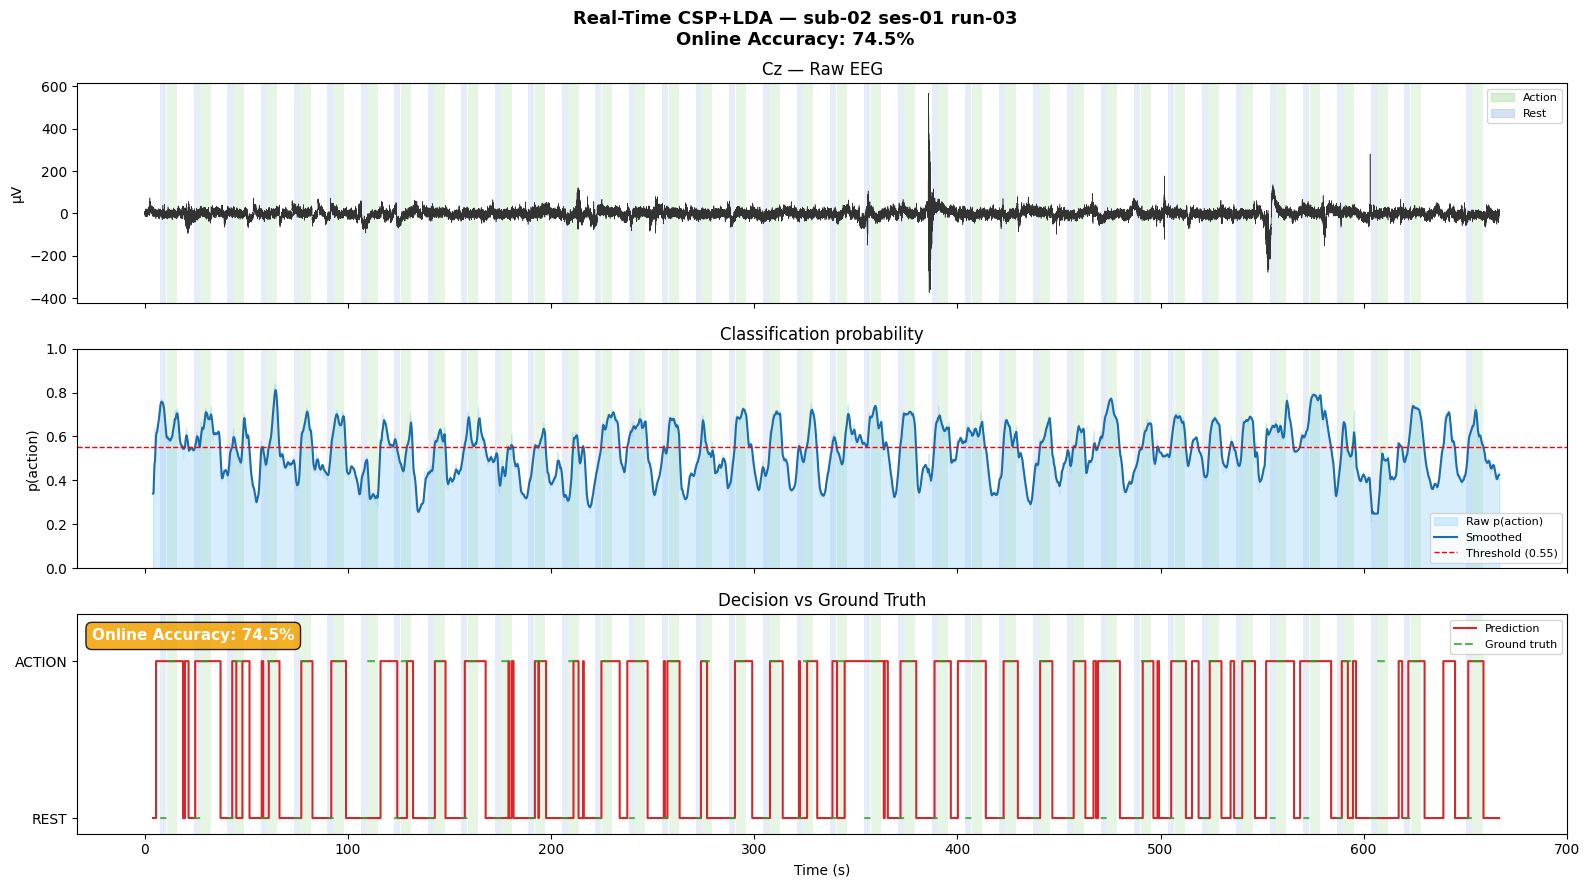

acc=74.5%  → saved realtime_figures/realtime_csp_sub02.png
sub-03: streaming… 

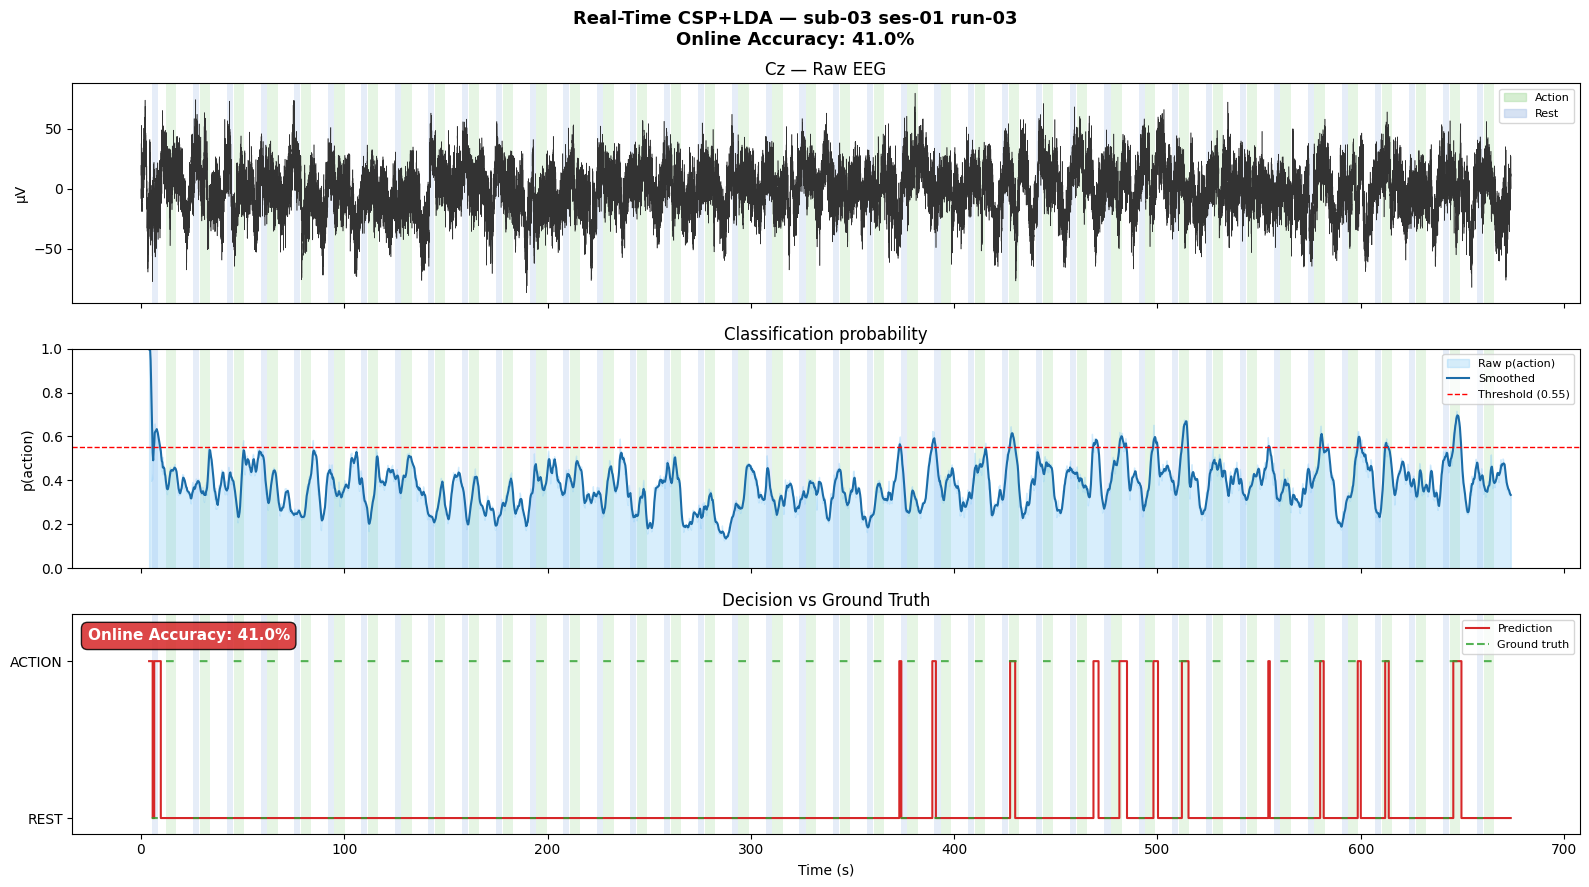

acc=41.0%  → saved realtime_figures/realtime_csp_sub03.png
sub-04: streaming… 

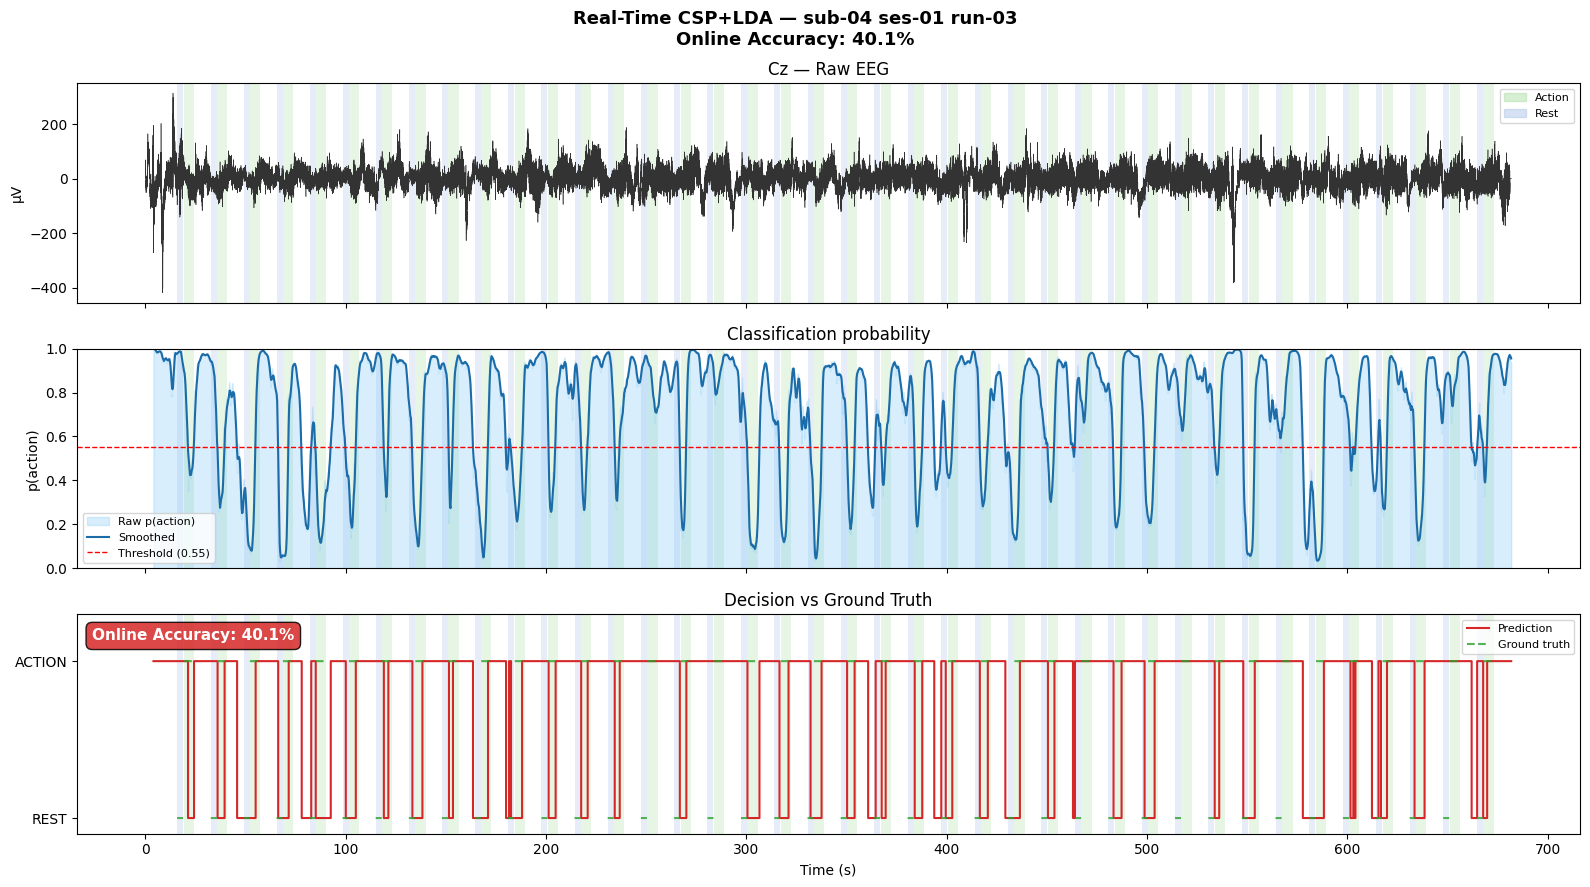

acc=40.1%  → saved realtime_figures/realtime_csp_sub04.png
sub-05: streaming… 

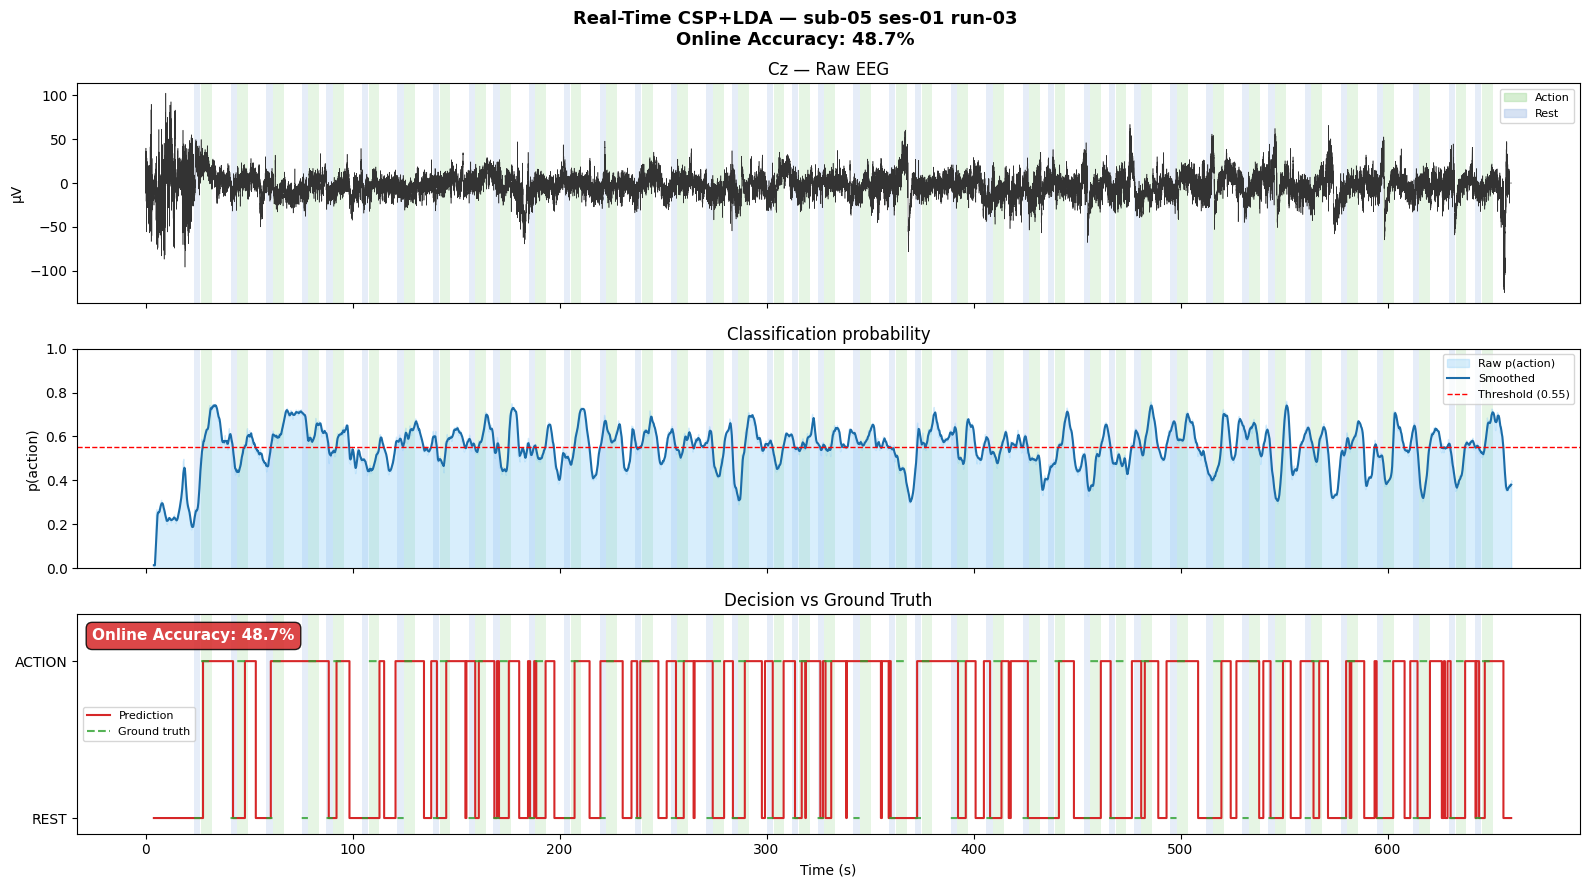

acc=48.7%  → saved realtime_figures/realtime_csp_sub05.png
sub-06: streaming… 

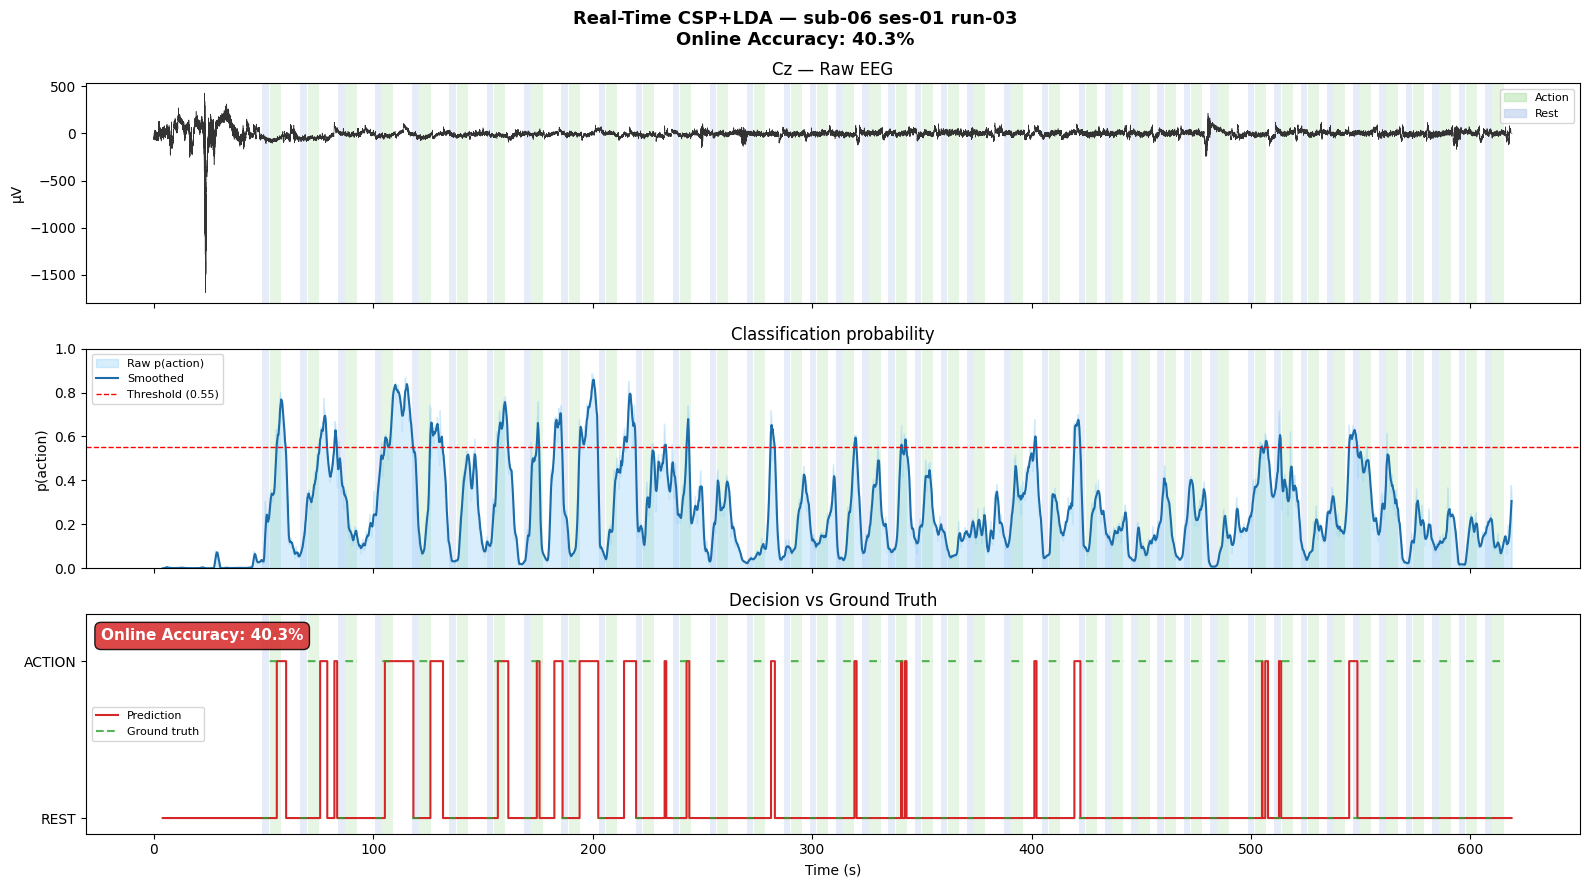

acc=40.3%  → saved realtime_figures/realtime_csp_sub06.png
sub-07: streaming… 

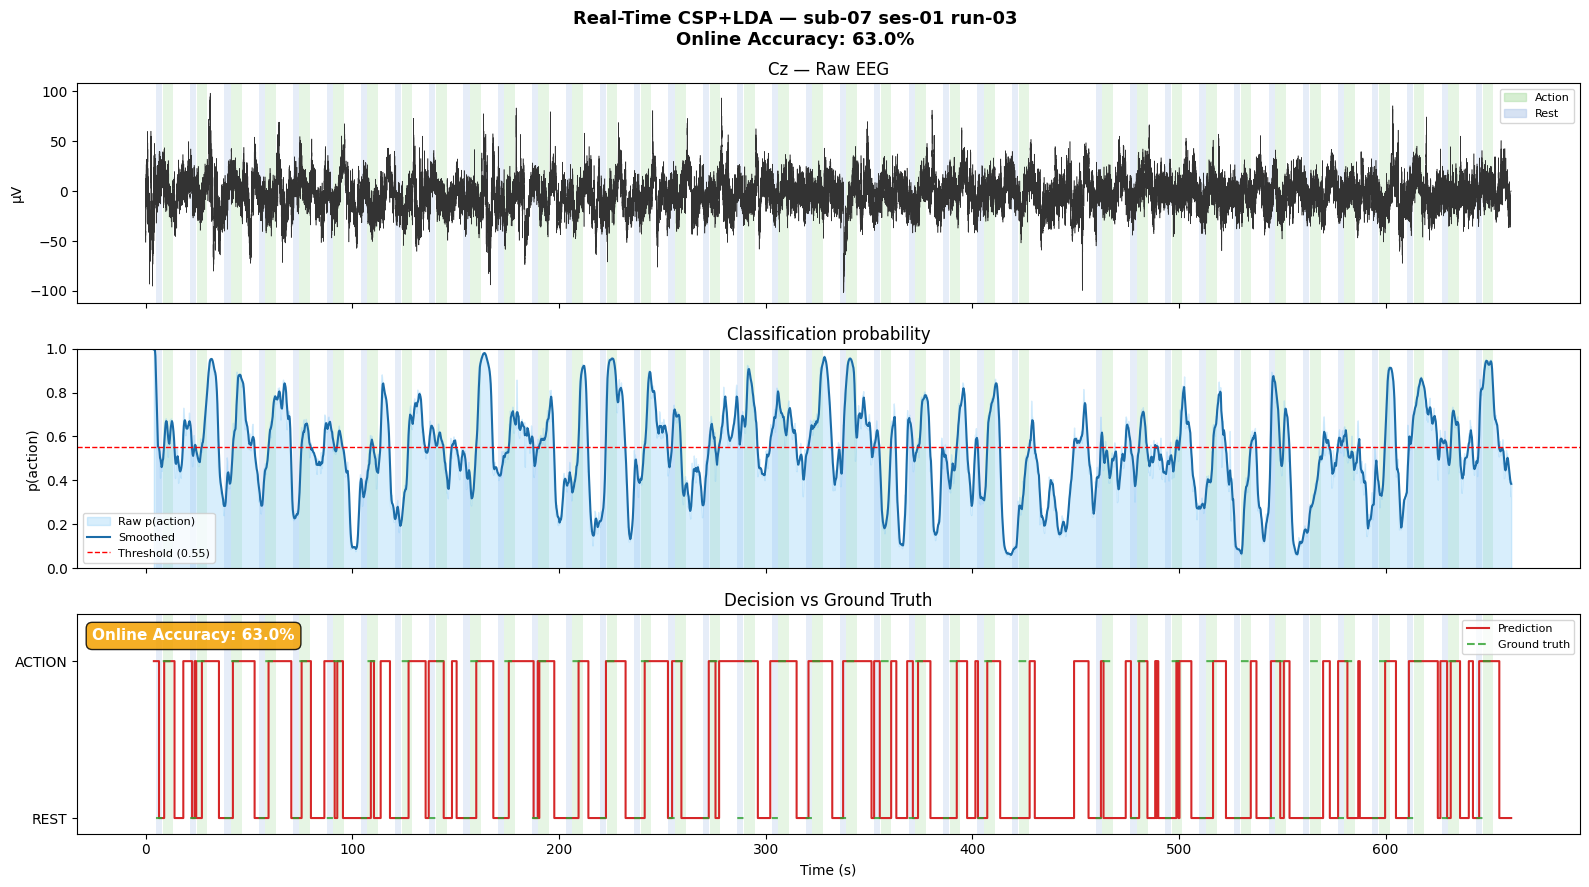

acc=63.0%  → saved realtime_figures/realtime_csp_sub07.png
sub-08: streaming… 

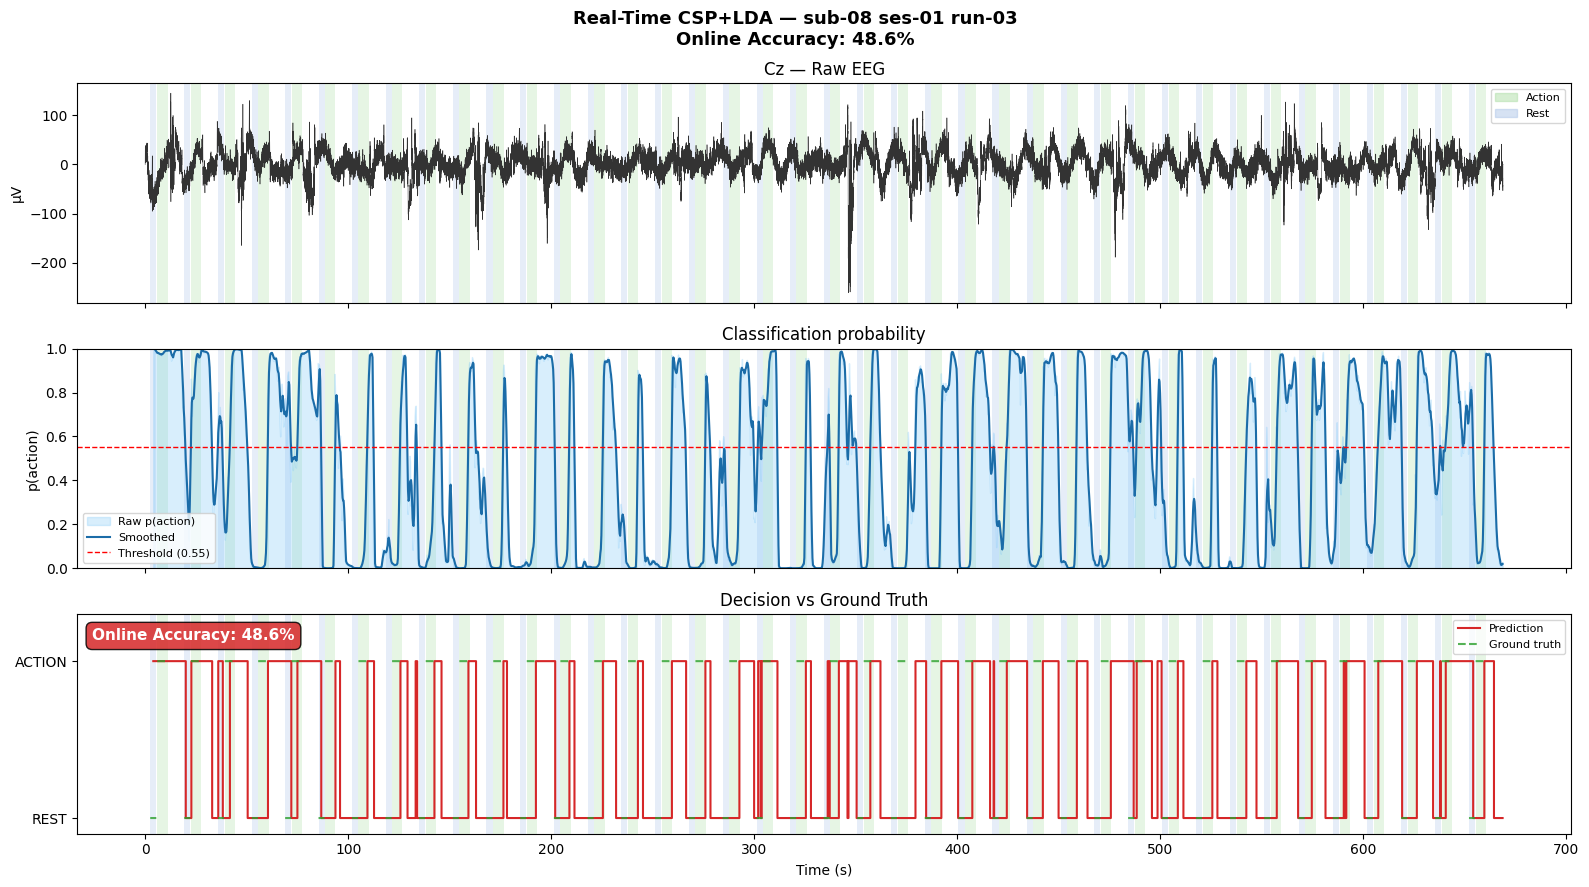

acc=48.6%  → saved realtime_figures/realtime_csp_sub08.png
sub-09: streaming… 

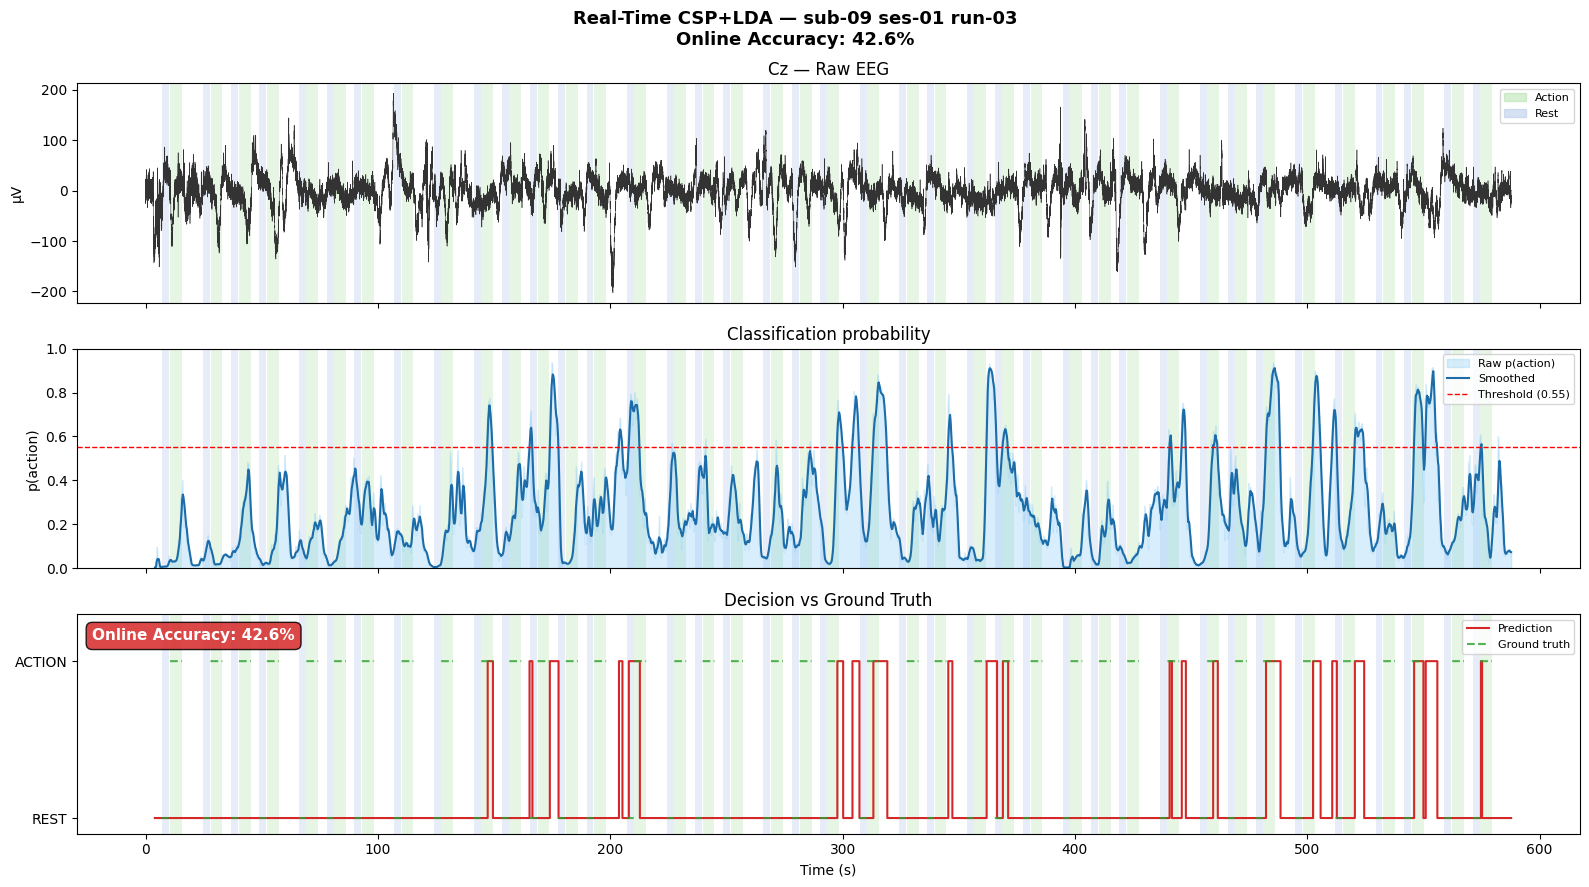

acc=42.6%  → saved realtime_figures/realtime_csp_sub09.png
sub-10: streaming… 

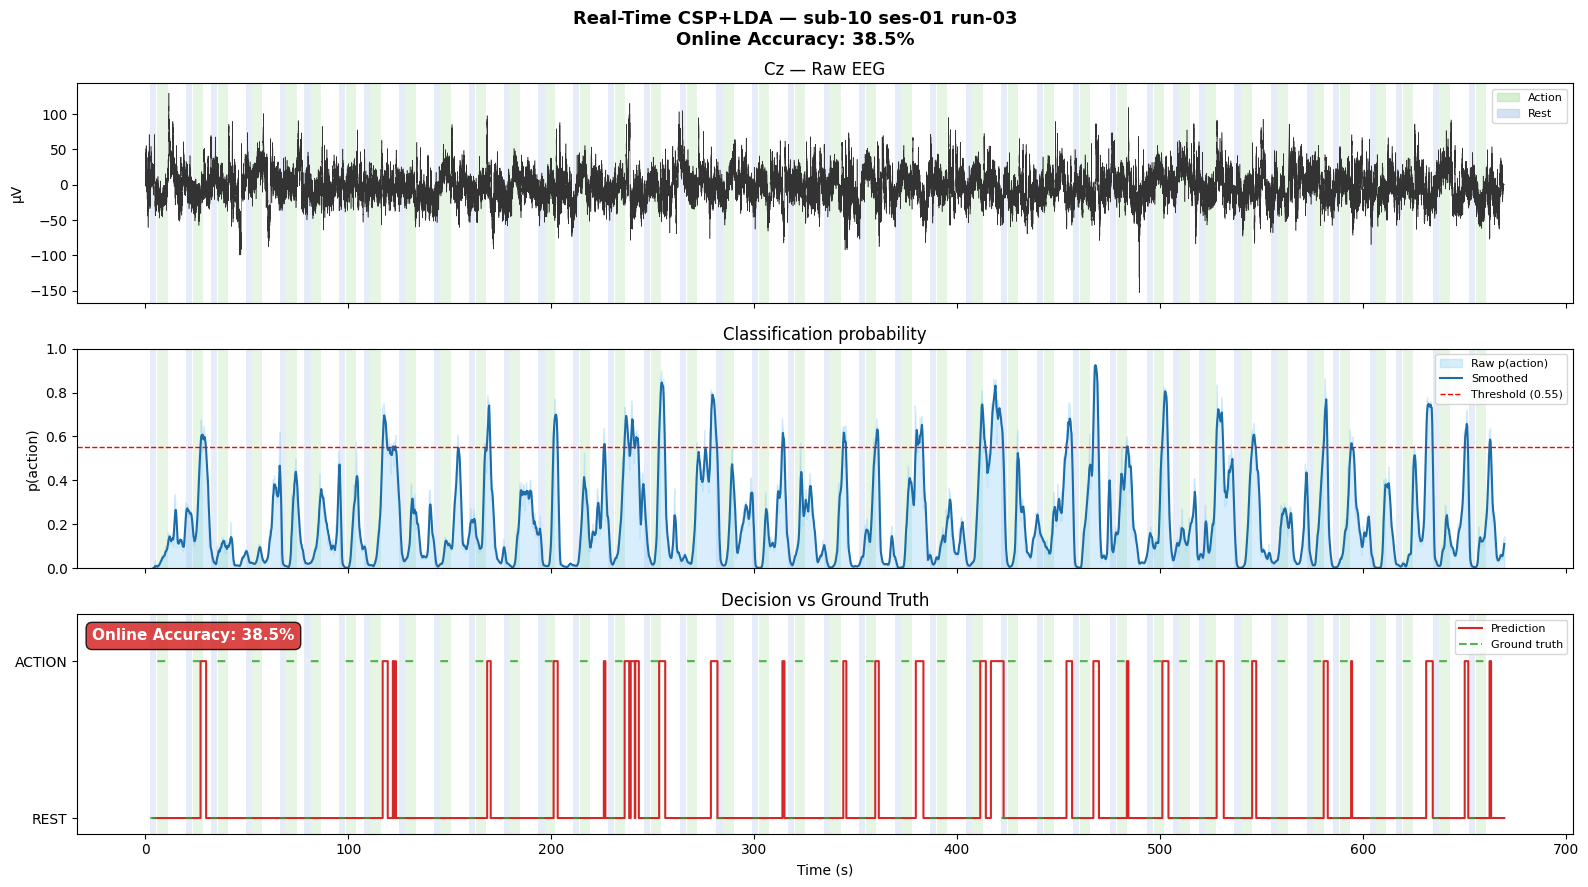

acc=38.5%  → saved realtime_figures/realtime_csp_sub10.png
sub-11: streaming… 

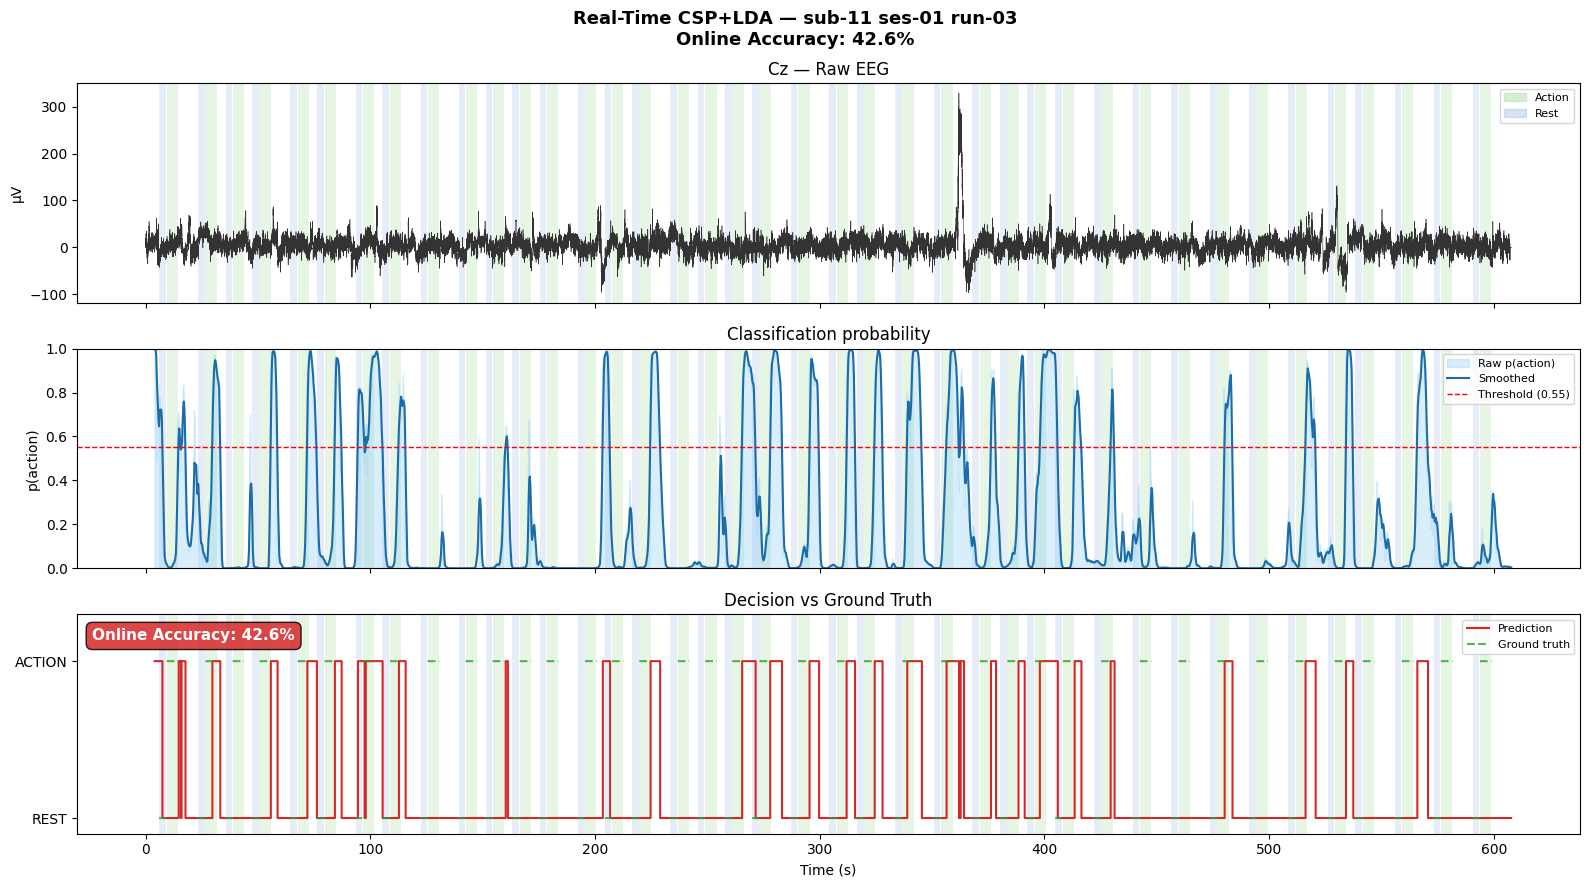

acc=42.6%  → saved realtime_figures/realtime_csp_sub11.png

  Real-Time Summary — CSP+LDA
Subject        Online Acc
──────────────────────────
sub-01           40.7%  ████████
sub-02           74.5%  ██████████████
sub-03           41.0%  ████████
sub-04           40.1%  ████████
sub-05           48.7%  █████████
sub-06           40.3%  ████████
sub-07           63.0%  ████████████
sub-08           48.6%  █████████
sub-09           42.6%  ████████
sub-10           38.5%  ███████
sub-11           42.6%  ████████
──────────────────────────
MEAN                47.3%

✅ Figures saved in: realtime_figures/


In [5]:
def stream_subject(model_or_pipe, mode, sub, ses, run,
                   epoch_len=4.0, step_len=0.25, smooth_win=5, threshold=0.55):
    """
    Stream one recording and return (online_acc, fig) so we can
    embed the accuracy in the saved figure.
    mode: 'nn' | 'csp' | 'svm'
    """
    edf_path    = build_path(ROOT, sub, ses, run, "eeg.edf")
    events_path = build_path(ROOT, sub, ses, run, "events.tsv")
    if not os.path.exists(edf_path):
        print(f"  ⚠️  EDF not found: {edf_path}")
        return None, None

    raw_rt = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
    avail  = [c for c in EEG_CHANNELS if c in raw_rt.ch_names]
    raw_rt.pick(avail)
    data   = raw_rt.get_data()
    n_ch, n_samples = data.shape
    times  = np.arange(n_samples) / SFREQ

    ev_rt = pd.read_csv(events_path, sep="\t")
    gt    = np.full(n_samples, -1, dtype=int)
    for _, row in ev_rt.iterrows():
        s = int(row["sample"]); d = int(row["duration"] * SFREQ)
        gt[s:s+d] = 1 if row["trial_type"] == "action" else 0

    sos     = butter(4, [FMIN, FMAX], btype="bandpass", fs=SFREQ, output="sos")
    zi      = np.stack([sosfilt_zi(sos)] * n_ch, axis=1)
    epoch_s = int(epoch_len * SFREQ)
    step_s  = int(step_len  * SFREQ)
    buffer  = np.zeros((n_ch, epoch_s), dtype=np.float32)
    prob_q  = deque(maxlen=smooth_win)
    decisions, buf_count = [], 0

    for i in range(n_samples):
        for c in range(n_ch):
            out, zi[:,c] = sosfilt(sos, data[c:c+1, i], zi=zi[:,c])
            buffer[c]    = np.roll(buffer[c], -1)
            buffer[c,-1] = out[0]
        buf_count += 1
        if i >= epoch_s and buf_count >= step_s:
            buf_count = 0
            X_rt = buffer.copy()
            X_rt = (X_rt - X_rt.mean(1,keepdims=True)) / (X_rt.std(1,keepdims=True)+1e-8)
            if mode == "nn":
                t_in = torch.tensor(X_rt, dtype=torch.float32).unsqueeze(0).to(DEVICE)
                with torch.no_grad():
                    p = torch_func.softmax(model_or_pipe(t_in), dim=1)[0,1].item()
            elif mode == "csp":
                p = model_or_pipe["pipe"].predict_proba(X_rt[np.newaxis])[0,1]
            elif mode == "svm":
                feats = extract_bandpower(X_rt[np.newaxis], model_or_pipe["ch_names"])
                p     = model_or_pipe["pipe"].predict_proba(feats)[0,1]
            prob_q.append(p)
            sm  = float(np.mean(prob_q))
            decisions.append((i, p, sm, int(sm >= threshold)))

    if not decisions:
        return None, None

    dec_arr      = np.array(decisions)
    dec_samples  = dec_arr[:,0].astype(int)
    raw_probs    = dec_arr[:,1]
    smooth_probs = dec_arr[:,2]
    dec_labels   = dec_arr[:,3].astype(int)
    dec_times    = dec_samples / SFREQ

    # ── Online accuracy
    labeled = gt[dec_samples] >= 0
    if labeled.sum() > 0:
        online_acc = (gt[dec_samples[labeled]] == dec_labels[labeled]).mean() * 100
    else:
        online_acc = float("nan")

    # ── Build figure with accuracy embedded
    mode_label = {"nn": RT_ARCH_LABEL, "csp": "CSP+LDA", "svm": "Band-Power SVM"}[mode]
    fig, axes  = plt.subplots(3, 1, figsize=(16, 9), sharex=True)

    # Main title includes accuracy
    fig.suptitle(
        f"Real-Time {mode_label} — sub-{sub:02d} ses-{ses:02d} run-{run:02d}\n"
        f"Online Accuracy: {online_acc:.1f}%",
        fontsize=13, fontweight="bold"
    )

    for ax in axes:
        for _, row in ev_rt.iterrows():
            col = "#AEDEA7" if row["trial_type"] == "action" else "#AEC6E8"
            ax.axvspan(row["onset"], row["onset"]+row["duration"],
                       color=col, alpha=0.3, lw=0)

    cz = avail.index("Cz") if "Cz" in avail else 0
    axes[0].plot(times, data[cz]*1e6, lw=0.4, color="#333")
    axes[0].set_ylabel("µV")
    axes[0].set_title("Cz — Raw EEG")
    axes[0].legend(
        handles=[mpatches.Patch(color="#AEDEA7", alpha=0.5, label="Action"),
                 mpatches.Patch(color="#AEC6E8", alpha=0.5, label="Rest")],
        loc="upper right", fontsize=8)

    axes[1].fill_between(dec_times, raw_probs, alpha=0.3,
                          color="#7FC8F8", label="Raw p(action)")
    axes[1].plot(dec_times, smooth_probs, lw=1.5, color="#1B6CA8", label="Smoothed")
    axes[1].axhline(threshold, color="r", ls="--", lw=1,
                     label=f"Threshold ({threshold})")
    axes[1].set_ylim(0, 1); axes[1].set_ylabel("p(action)")
    axes[1].set_title("Classification probability")
    axes[1].legend(fontsize=8)

    gt_vis = np.where(gt >= 0, gt.astype(float), np.nan)
    axes[2].step(dec_times, dec_labels, lw=1.5, color="#D62728",
                  where="post", label="Prediction")
    axes[2].plot(times, gt_vis, lw=1.5, color="#2CA02C",
                  ls="--", alpha=0.8, label="Ground truth")
    axes[2].set_ylim(-0.1, 1.3)
    axes[2].set_yticks([0, 1])
    axes[2].set_yticklabels(["REST", "ACTION"])
    axes[2].set_xlabel("Time (s)")
    axes[2].set_title("Decision vs Ground Truth")
    axes[2].legend(fontsize=8)

    # Accuracy annotation box on the decision panel
    axes[2].annotate(
        f"Online Accuracy: {online_acc:.1f}%",
        xy=(0.01, 0.88), xycoords="axes fraction",
        fontsize=11, fontweight="bold",
        color="white",
        bbox=dict(boxstyle="round,pad=0.4",
                  fc="#D62728" if online_acc < 60 else
                     "#F4A100" if online_acc < 75 else
                     "#2CA02C",
                  alpha=0.85)
    )

    plt.tight_layout()
    return online_acc, fig

RT_ARCH_LABEL = 'CSP+LDA'

# ══════════════════════════════════════════════════════
# Real-time — ALL subjects
# ══════════════════════════════════════════════════════
RT_SUBJECTS = list(range(1, 12))
RT_SESSION  = 1
RT_RUN      = 3
THRESHOLD   = 0.55
os.makedirs("realtime_figures", exist_ok=True)

rt_summary = []

for sub in RT_SUBJECTS:
    ckpt_path = f"checkpoint_csp_sub{sub:02d}_run{RT_RUN}.pkl"
    if not os.path.exists(ckpt_path):
        print(f"sub-{sub:02d}: ⚠️  checkpoint not found — skipping")
        continue

    saved = joblib.load(ckpt_path)
    print(f"sub-{sub:02d}: streaming…", end=" ", flush=True)
    online_acc, fig = stream_subject(
        saved, "csp", sub, RT_SESSION, RT_RUN, threshold=THRESHOLD)

    if fig is not None:
        out_path = f"realtime_figures/realtime_csp_sub{sub:02d}.png"
        fig.savefig(out_path, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        rt_summary.append({"subject": sub, "online_acc": online_acc})
        print(f"acc={online_acc:.1f}%  → saved {out_path}")
    else:
        print("no output")

print(f"\n{'='*40}")
print(f"  Real-Time Summary — CSP+LDA")
print(f"{'='*40}")
print(f"{'Subject':<12} {'Online Acc':>12}")
print("─" * 26)
for r in rt_summary:
    bar = "█" * int(r["online_acc"] / 5)
    print(f"sub-{r['subject']:02d}       {r['online_acc']:>8.1f}%  {bar}")
if rt_summary:
    mean_acc = np.mean([r["online_acc"] for r in rt_summary])
    print("─" * 26)
    print(f"{'MEAN':<12} {mean_acc:>11.1f}%")
    print(f"\n✅ Figures saved in: realtime_figures/")